# Ajedrez online — Entrega 3: modelado del resultado antes y durante la partida

**Proyecto Integrador — Ciencia de Datos, UTN FRM 2026**

**Pregunta.** ¿Qué tan bien se predice quién gana una partida de ajedrez online, y cuánto le falta para terminar, **antes de que empiece y a medida que avanza**?

**Qué cambió desde la Entrega 2.** En la Entrega 2 el dataset no tenía variables reales para predecir: sólo el rating posterior, que trae el resultado adentro. Ahora cada fila es una partida vista en un momento dado (partida × corte de plies), con la posición y los relojes de ese momento, el rating **previo** reconstruido sin fuga y la forma reciente de cada jugador. El objetivo sigue siendo `resultado`.

**Qué hay en este notebook.** El modelado de la Entrega 3:

1. el planteo: métrica, piso y validación, declarados antes de entrenar;
2. tres modelos comparados con la misma validación cruzada;
3. qué pasa si la validación se arma de otra forma;
4. el ajuste del elegido;
5. la decisión sobre la clase chica;
6. las columnas que no sirvieron;
7. el modelo final, medido **una vez** sobre el test y leído.

Después, la comprobación de que el modelo sirve en cualquier jugada, la duración restante como objetivo secundario y el modelo guardado para la app de la Entrega 4.

El notebook 03 fue una exploración: un modelo por corte, una sola partición y decisiones tomadas mirando el test. Acá todo lo que se elige se elige con validación cruzada sobre train, y se entrena **un solo modelo** con el corte como columna, que es el que va a usar la app.

**Fuente.** El Parquet tidy (`partidas_ajedrez_clean.parquet`) y la tabla de cortes (`partidas_cortes.parquet`, un corte cada 5 plies del 0 al 120) que genera el DAG, más el rating previo y la forma reciente reconstruidos desde los JSON crudos. Corre con **Restart & Run All** en unos 20 minutos, con la semilla del config.

## 1 · Planteo

Cuatro decisiones, tomadas antes del primer modelo.

**Qué se predice.** `resultado` (Gana Blancas / Empate / Gana Negras) en cada corte, una clasificación de tres clases. Una fila es una partida vista después de `corte_ply` medio-movimientos: el 0 es antes de mover, y llega hasta el 120. Con un solo modelo y el corte como columna, la pregunta "antes y durante" es una sola curva.

**La métrica: log-loss.** La app muestra **probabilidades** jugada a jugada, y el error caro es mostrar 85 % de victoria blanca en una partida que ganan las negras. La log-loss mide exactamente eso: cuánta probabilidad le dio el modelo a lo que efectivamente pasó, y castiga más cuanto más seguro estaba de lo contrario. La accuracy no lo ve, porque para ella es lo mismo acertar con 51 % que con 99 %. Las clases están desparejas (el empate es ~6 %), así que se informan además el **F1 macro**, que ve a la clase chica, y el **recall de Empate**.

**El piso.** `DummyClassifier(strategy="prior")`: siempre las proporciones de train, sin mirar ninguna columna. Se mide con la misma validación que todo lo demás.

**La validación imita el uso.** Las filas se repiten de tres formas, y cada una pesa en cómo se arman los pedazos:

| Las filas se repiten… | Cómo se usa el modelo | Cómo se arman los pedazos |
|---|---|---|
| por **partida**: hasta 25 cortes de la misma partida, con el mismo resultado | se predice una partida que no se vio | una partida nunca queda de los dos lados |
| en el **tiempo** | se predicen las partidas que vienen | se entrena con lo anterior y se valida con lo posterior |
| por **jugador**: hasta 1.000 partidas de cada cuenta | la app predice las próximas partidas de jugadores que ya tienen historial (de ahí salen su rating previo y su forma) | el mismo jugador puede estar de los dos lados, a propósito |

En concreto:

- **Test.** Las partidas que empiezan después del percentil 80 de `StartTime`. Train son las que terminaron antes, y las que cruzan ese momento se descartan.
- **Validación cruzada dentro de train.** `TimeSeriesSplit` de 5 pedazos sobre las **partidas ordenadas por inicio**, que después se expanden a sus cortes (`src/model_validation.py`). Se le pasa a `cross_validate` y a `GridSearchCV` como `cv=`.
- **Qué pasa si se arman distinto.** La sección 4 mide qué pasa si los pedazos se arman al azar sobre filas, y qué pasa con jugadores que el modelo nunca vio.
- **Costo.** Train tiene casi un millón de filas. La comparación, la grilla y las pruebas de columnas usan una muestra del 25 % de las **partidas** de train (no de las filas), con la semilla del config. El modelo final se entrena con todo train.

**Todo adentro de un pipeline.** La imputación, el escalado y la codificación del ritmo van adentro del `Pipeline` que se entrena, así que en cada pedazo se ajustan sólo con su parte de entrenamiento. Tres grupos de columnas se calculan **afuera**, porque necesitan el historial de partidas de cada jugador:

- el rating previo;
- la forma reciente;
- las tasas del matchup de apertura.

Ninguno usa una estadística de la tabla entera: el valor de una partida sale **sólo de partidas que terminaron antes de que empiece**. Daría lo mismo calcularlo con o sin el test, y es lo mismo que tendría la app en ese momento. Lo garantizan los tests `test_recent_form_only_looks_at_earlier_games` y `test_prior_rating_is_the_rating_after_the_previous_own_game`.

**Reglas para decidir**, fijadas antes de ver los números. Comparan la log-loss **pedazo a pedazo**, porque los cinco pedazos son los mismos para todos los modelos:

- **Modelo.** Uno más complejo reemplaza a la regresión logística sólo si le gana por más que el desvío de la diferencia. Si los dos ensambles le ganan y entre ellos la diferencia no supera su desvío, queda el más rápido de entrenar.
- **Hiperparámetros.** La configuración de menor log-loss media en la grilla.
- **Clase chica.** `class_weight="balanced"` entra sólo si mejora la log-loss, que es la métrica declarada.
- **Columnas.** Un grupo entra si mejora la log-loss global o la del corte 0 por más que el desvío de la diferencia, sin empeorar la otra por más que su desvío. Un grupo sale si quitarlo mejora de la misma forma.

In [1]:
from pathlib import Path
import json
import sys
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, log_loss, make_scorer, mean_absolute_error, recall_score
from sklearn.model_selection import GridSearchCV, GroupKFold, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.model_validation import temporal_game_folds
from src.player_selection import load_selection
from src.predict import (
    CATEGORICAL, CLOCKS, FORM, LIVE, MODEL_PATH, PRE_GAME, RESULT_ORDER, cargar_modelo, model_frame, predecir,
)
from src.rating_history import add_prior_ratings, add_recent_form, reconstruct_prior_ratings, reconstruct_recent_form
from src.utils import load_config

config = load_config(PROJECT_ROOT / "config" / "config.yaml")
RANDOM_STATE = config["processing"]["random_state"]
CUTS = config["live_prediction"]["cortes_ply"]
REFERENCE_CUTS = config["live_prediction"]["cortes_referencia"]
# Model comparison, grid and column tests run on this share of the training GAMES (not rows).
CV_GAME_FRACTION = 0.25
N_SPLITS = 5
NOTEBOOK_START = time.perf_counter()

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

## 2 · Datos y partición

La tabla de cortes sólo guarda lo que cambia jugada a jugada. El contexto fijo de la partida se une desde el tidy por `GameUrl` (muchos a uno, con su assert de conteo): el ritmo, el control de tiempo, el torneo, el rating previo, la forma reciente y el matchup de apertura. El matchup se lee de los plies 1 y 2, así que en el corte 0 todavía es una jugada futura: ahí queda "aún no jugado", y sus tasas, vacías. `jugador` es la cuenta seleccionada de la partida; no es una columna del modelo, sólo agrupa para la sección 4.

In [2]:
games = pd.read_parquet(PROJECT_ROOT / config["paths"]["clean_parquet"])
cuts = pd.read_parquet(PROJECT_ROOT / config["paths"]["cortes_parquet"])
assert sorted(cuts["corte_ply"].unique()) == sorted(CUTS), "La tabla de cortes no coincide con live_prediction.cortes_ply"

usernames = load_selection(PROJECT_ROOT / config["player_selection"]["selection_path"])
template = config["chess_com"]["raw_filename_template"]
raw_paths = {u: PROJECT_ROOT / config["paths"]["raw_dir"] / template.format(username=u) for u in usernames}
games = add_prior_ratings(games, reconstruct_prior_ratings(raw_paths))
games = add_recent_form(games, reconstruct_recent_form(raw_paths, games[["GameUrl", "StartTime"]]))

# The selected account of each game (white when both are selected, 14 games): only used to group in section 4.
selected = {u.lower() for u in usernames}
white_selected = games["White"].str.lower().isin(selected)
games["jugador"] = games["White"].str.lower().where(white_selected, games["Black"].str.lower())
assert games["jugador"].isin(selected).all(), "Una partida sin cuenta seleccionada"

MATCHUP = ["matchup_apertura", "tasa_blancas_hist", "tasa_tablas_hist", "tasa_negras_hist"]
LEAKY = [
    "WhiteElo", "BlackElo", "diferencia_elo", "elo_promedio", "nivel_promedio", "es_sorpresa",
    "Termination", "cantidad_jugadas", "EndTime", "ECO", "Opening", "familia_apertura",
]
assert not set(LEAKY) & set(PRE_GAME + LIVE + FORM + MATCHUP), "Una columna con fuga quedó entre las candidatas"

context_columns = ["GameUrl", "StartTime", "EndTime", "jugador", *PRE_GAME, *FORM, *MATCHUP]
rows_before = len(cuts)
data = cuts.merge(games[context_columns], on="GameUrl", how="left", validate="many_to_one")
assert len(data) == rows_before, "Fan-out detectado al unir el contexto de la partida"
# matchup_apertura is read from plies 1 and 2: at cut 0 it is still a future move, and so are its rates.
not_played = data["corte_ply"] < 2
data["matchup_apertura"] = data["matchup_apertura"].astype(str).where(~not_played, "aún no jugado")
data.loc[not_played, MATCHUP[1:]] = np.nan
print(f"Filas (partida, corte): {len(data):,} de {data['GameUrl'].nunique():,} partidas, {data['corte_ply'].nunique()} cortes")

coverage = pd.Series({
    "rating previo de blancas": games["elo_blancas_previo"].notna().mean(),
    "rating previo de negras": games["elo_negras_previo"].notna().mean(),
    "forma reciente de blancas": games["forma_ultimas10_blancas"].notna().mean(),
    "forma reciente de negras": games["forma_ultimas10_negras"].notna().mean(),
}, name="% de partidas").mul(100)
display(coverage.to_frame().round(1))

2026-10-22 13:51:48 - src.rating_history - INFO - Rating previo reconstruido: blancas en 40427 partidas, negras en 40431.


2026-10-22 13:51:49 - src.rating_history - INFO - Forma reciente: 78990 partidas con historial de 10 previas de al menos un lado.


Filas (partida, corte): 1,216,417 de 80,697 partidas, 25 cortes


,% de partidas
rating previo de blancas,49.800
rating previo de negras,49.900
forma reciente de blancas,48.700
forma reciente de negras,48.700


In [3]:
split_time = games["StartTime"].quantile(0.8)
train_games = set(games.loc[games["EndTime"] < split_time, "GameUrl"])
test_games = set(games.loc[games["StartTime"] >= split_time, "GameUrl"])
assert not train_games & test_games

data["particion"] = np.select(
    [data["GameUrl"].isin(train_games), data["GameUrl"].isin(test_games)], ["train", "test"], default="descartada"
)
train = data[data["particion"] == "train"].reset_index(drop=True)
test = data[data["particion"] == "test"].reset_index(drop=True)
print(f"Corte temporal: {split_time:%Y-%m-%d %H:%M} UTC")
print(f"Train: {len(train_games):,} partidas, {len(train):,} filas · Test: {len(test_games):,} partidas, {len(test):,} filas · "
      f"descartadas por cruzar el corte: {len(games) - len(train_games) - len(test_games)} partidas")
display(
    pd.crosstab(data["particion"], data["resultado"], normalize="index").mul(100).round(2)
    .reindex(columns=RESULT_ORDER).rename_axis(None, axis=1)
)

Corte temporal: 2026-06-16 01:08 UTC
Train: 64,556 partidas, 972,887 filas · Test: 16,140 partidas, 243,516 filas · descartadas por cruzar el corte: 1 partidas


,Gana Blancas,Empate,Gana Negras
particion,,,
descartada,100.000,0.000,0.000
test,47.470,7.580,44.950
train,47.310,8.530,44.170


In [4]:
cv_games = pd.Series(sorted(train_games)).sample(frac=CV_GAME_FRACTION, random_state=RANDOM_STATE)
cv_data = train[train["GameUrl"].isin(set(cv_games))].reset_index(drop=True)
y_cv = cv_data["resultado"].astype(str).to_numpy()
FOLDS = temporal_game_folds(cv_data["GameUrl"], cv_data["StartTime"], n_splits=N_SPLITS)

fold_rows = []
for k, (fit_rows, val_rows) in enumerate(FOLDS, start=1):
    fit_part, val_part = cv_data.iloc[fit_rows], cv_data.iloc[val_rows]
    assert set(fit_part["GameUrl"]).isdisjoint(val_part["GameUrl"]), "Una partida quedó de los dos lados"
    assert fit_part["StartTime"].max() <= val_part["StartTime"].min(), "Se valida con una partida anterior"
    fold_rows.append({
        "fold": k,
        "partidas entrenamiento": fit_part["GameUrl"].nunique(), "filas entrenamiento": len(fit_part),
        "partidas validación": val_part["GameUrl"].nunique(), "filas validación": len(val_part),
        "validación desde": f"{val_part['StartTime'].min():%Y-%m-%d}", "validación hasta": f"{val_part['StartTime'].max():%Y-%m-%d}",
    })
print(f"Muestra para la validación cruzada: {cv_data['GameUrl'].nunique():,} partidas, {len(cv_data):,} filas")
display(pd.DataFrame(fold_rows).set_index("fold"))

Muestra para la validación cruzada: 16,139 partidas, 243,463 filas


,partidas entrenamiento,filas entrenamiento,partidas validación,filas validación,validación desde,validación hasta
fold,,,,,,
1,2694,41928,2689,39205,2020-12-10,2023-03-13
2,5383,81133,2689,39605,2023-03-13,2024-09-03
3,8072,120738,2689,41004,2024-09-03,2025-09-26
4,10761,161742,2689,40834,2025-09-27,2026-03-31
5,13450,202576,2689,40887,2026-03-31,2026-06-16


**Lectura.**

- **Partición.** El corte temporal cae el 16/06/2026. Train son 64.556 partidas (972.887 filas) y test, las 16.140 que empezaron después (243.516 filas). Sólo una partida cruza el corte y se descarta.
- **Resultados.** Las proporciones son parecidas en los dos lados. El empate es el 8,5 % de las filas de train y el 7,6 % de las de test. Son filas, no partidas: las partidas largas aportan más cortes y empatan más, por eso el empate pesa más que el ~6 % de las partidas.
- **Rating previo y forma.** Existen para la mitad de cada lado, que es el lado de la cuenta seleccionada. El del rival queda vacío.
- **Muestra para la validación cruzada.** Son 16.139 partidas de train (243.463 filas). Cada pedazo de validación tiene unas 2.690 partidas, siempre posteriores a las de entrenamiento, y los cinco juntos van de diciembre de 2020 a junio de 2026.
- **El primer pedazo es el más difícil.** Entrena con sólo 2.694 partidas, y eso se va a notar en los desvíos.

## 3 · Piso y comparación de modelos

Todos los modelos son un `Pipeline` completo y usan las mismas columnas: pre-partida + en vivo (`PRE_GAME + LIVE` de `src/predict.py`). La forma reciente y el matchup se prueban en la sección 7.

| Modelo | Qué es | Preparación adentro del pipeline |
|---|---|---|
| **Piso** | `DummyClassifier(strategy="prior")`: siempre las proporciones de train | ninguna |
| **Regresión logística** | el modelo simple, la referencia | imputación por mediana con indicador de faltante, escalado, one-hot del ritmo |
| **Random forest** | 200 árboles; hojas de al menos 50 filas y 30 % de las filas por árbol, por costo | imputación con indicador, one-hot del ritmo |
| **Gradient boosting** | `HistGradientBoostingClassifier` con sus valores por defecto (sin early stopping, para que sea reproducible) | ninguna: maneja los NaN solo; el ritmo entra como categórica |

Se miden con `cross_validate` y los pedazos de la sección 2. La tabla muestra la media de los 5 pedazos, con su desvío (±). "log_loss corte 0" es la predicción antes de mover. "log_loss train" es la misma métrica sobre la parte de entrenamiento de cada pedazo: si es mucho menor que la de validación, el modelo memoriza.

In [5]:
def neg_log_loss_corte0(estimator, X, y):
    """Scorer: log-loss before the first move (cut 0), the 'antes de empezar' half of the question."""
    at_start = (X["corte_ply"] == 0).to_numpy()
    return -log_loss(np.asarray(y)[at_start], estimator.predict_proba(X[at_start]), labels=estimator.classes_)


SCORING = {
    # Explicit labels: a validation fold without some class must still be scored against all three.
    "log_loss": make_scorer(log_loss, greater_is_better=False, response_method="predict_proba", labels=sorted(RESULT_ORDER)),
    "f1_macro": "f1_macro",
    "recall_empate": make_scorer(recall_score, labels=["Empate"], average="macro", zero_division=0),
    "log_loss_corte0": neg_log_loss_corte0,
}
# sklearn scorers are "greater is better": log-losses come back negative and are flipped for reading.
NEGATED = {"log_loss", "log_loss_corte0"}


def make_classifier(family, columns):
    """A full Pipeline: preprocessing is fitted inside each training fold, never on the whole table."""
    categorical = [c for c in columns if c in CATEGORICAL]
    numeric = [c for c in columns if c not in CATEGORICAL]
    if family == "piso":
        return DummyClassifier(strategy="prior")
    if family == "logistica":
        prep = ColumnTransformer([
            ("categoricas", OneHotEncoder(handle_unknown="ignore"), categorical),
            ("numericas", Pipeline([
                ("imputar", SimpleImputer(strategy="median", add_indicator=True)), ("escalar", StandardScaler()),
            ]), numeric),
        ])
        return Pipeline([("prep", prep), ("modelo", LogisticRegression(max_iter=2000))])
    if family == "bosque":
        prep = ColumnTransformer([
            ("categoricas", OneHotEncoder(handle_unknown="ignore"), categorical),
            ("numericas", SimpleImputer(strategy="median", add_indicator=True), numeric),
        ])
        forest = RandomForestClassifier(
            n_estimators=200, min_samples_leaf=50, max_samples=0.3, n_jobs=-1, random_state=RANDOM_STATE
        )
        return Pipeline([("prep", prep), ("modelo", forest)])
    if family == "boosting":
        # Native NaN support, so no imputer; categories go in as integer codes declared categorical.
        prep = ColumnTransformer(
            [("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical),
             ("numericas", "passthrough", numeric)],
            verbose_feature_names_out=False,
        ).set_output(transform="pandas")
        boosting = HistGradientBoostingClassifier(
            categorical_features=categorical, early_stopping=False, random_state=RANDOM_STATE
        )
        return Pipeline([("prep", prep), ("modelo", boosting)])
    raise ValueError(f"Familia desconocida: {family}")


def score_table(get, n_folds, fit_seconds):
    """Per-fold scores, log-losses back to positive numbers."""
    table = pd.DataFrame(
        {m: (-1 if m in NEGATED else 1) * np.asarray(get(f"test_{m}")) for m in SCORING},
        index=pd.RangeIndex(1, n_folds + 1, name="fold"),
    )
    table["log_loss_train"] = -np.asarray(get("train_log_loss"))
    table["segundos"] = fit_seconds
    return table


def run_cv(estimator, columns, cv=None, groups=None):
    """cross_validate on the CV sample with the temporal folds (or the cv given)."""
    result = cross_validate(
        estimator, model_frame(cv_data, columns), y_cv, groups=groups, cv=FOLDS if cv is None else cv,
        scoring=SCORING, return_train_score=True,
    )
    return score_table(lambda key: result[key], len(result["fit_time"]), result["fit_time"])


def summarize(scores_by_name):
    """Mean ± std across folds."""
    rows = []
    for name, s in scores_by_name.items():
        rows.append({
            "variante": name,
            "log_loss": s["log_loss"].mean(), "± log_loss": s["log_loss"].std(),
            "f1_macro": s["f1_macro"].mean(), "± f1_macro": s["f1_macro"].std(),
            "recall_empate": s["recall_empate"].mean(),
            "log_loss corte 0": s["log_loss_corte0"].mean(), "± corte 0": s["log_loss_corte0"].std(),
            "log_loss train": s["log_loss_train"].mean(),
            "segundos": s["segundos"].sum(),
        })
    return pd.DataFrame(rows).set_index("variante")


def paired_difference(scores, reference, metric="log_loss"):
    """Per-fold difference against a reference measured on the same folds (negative = better)."""
    return scores[metric].to_numpy() - reference[metric].to_numpy()

In [6]:
BASE_COLUMNS = PRE_GAME + LIVE
FAMILIES = {
    "Piso (prior)": "piso",
    "Regresión logística": "logistica",
    "Random forest": "bosque",
    "Gradient boosting": "boosting",
}
comparison = {name: run_cv(make_classifier(family, BASE_COLUMNS), BASE_COLUMNS) for name, family in FAMILIES.items()}
display(summarize(comparison))
print("Log-loss de cada pedazo:")
display(pd.DataFrame({name: s["log_loss"] for name, s in comparison.items()}))

,log_loss,± log_loss,f1_macro,± f1_macro,recall_empate,log_loss corte 0,± corte 0,log_loss train,segundos
variante,,,,,,,,,
Piso (prior),0.923,0.010,0.214,0.003,0.000,0.883,0.008,0.915,0.287
Regresión logística,0.854,0.018,0.406,0.006,0.008,0.879,0.011,0.832,49.241
Random forest,0.835,0.017,0.409,0.005,0.001,0.878,0.012,0.787,22.420
Gradient boosting,0.890,0.099,0.427,0.014,0.049,0.929,0.076,0.628,12.669


Log-loss de cada pedazo:


,Piso (prior),Regresión logística,Random forest,Gradient boosting
fold,,,,
1,0.927,0.879,0.857,1.059
2,0.920,0.851,0.835,0.869
3,0.926,0.859,0.842,0.877
4,0.907,0.829,0.810,0.810
5,0.935,0.852,0.829,0.833


In [7]:
# Decision rule from section 1, on the per-fold differences.
SIMPLE = "Regresión logística"
ENSEMBLES = ["Random forest", "Gradient boosting"]
decision_rows = []
for name in ENSEMBLES:
    diff = paired_difference(comparison[name], comparison[SIMPLE])
    decision_rows.append({"modelo": name, "diferencia media contra la logística": diff.mean(), "desvío de la diferencia": diff.std(ddof=1),
                          "le gana por más que el desvío": diff.mean() < -diff.std(ddof=1)})
decision = pd.DataFrame(decision_rows).set_index("modelo")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(decision)

winners = decision.index[decision["le gana por más que el desvío"]].tolist()
if not winners:
    CHOSEN_NAME = SIMPLE
elif len(winners) == 1:
    CHOSEN_NAME = winners[0]
else:
    between = paired_difference(comparison["Gradient boosting"], comparison["Random forest"])
    print(f"Gradient boosting − random forest: {between.mean():+.4f} ± {between.std(ddof=1):.4f}")
    if abs(between.mean()) > between.std(ddof=1):
        CHOSEN_NAME = "Gradient boosting" if between.mean() < 0 else "Random forest"
    else:
        CHOSEN_NAME = min(winners, key=lambda name: comparison[name]["segundos"].sum())  # tied: the cheaper one
CHOSEN_FAMILY = FAMILIES[CHOSEN_NAME]
print(f"Modelo elegido: {CHOSEN_NAME}")

,diferencia media contra la logística,desvío de la diferencia,le gana por más que el desvío
modelo,,,
Random forest,-0.0194,0.0035,True
Gradient boosting,0.0355,0.0830,False


Modelo elegido: Random forest


**Lectura.**

- **Contra el piso.** El piso da 0,923 de log-loss. La regresión logística lo mejora en 0,069 (0,854 ± 0,018) y el random forest en 0,088 (0,835 ± 0,017).
- **Bosque contra logística.** La diferencia que importa es la de cada pedazo. El bosque le gana a la logística en los cinco, por 0,019 de media con un desvío de 0,0035: la mejora es más de cinco veces el ruido. Por la regla de la sección 1, **queda el random forest**.
- **El gradient boosting con sus valores por defecto queda último** (0,890 ± 0,099), y es el que más memoriza: 0,628 de log-loss en train contra 0,890 en validación. El desvío alto viene del primer pedazo (1,059), que entrena con sólo 2.694 partidas. Con tasa de aprendizaje 0,1 y sin regularización, el boosting aprende de memoria esas ~42.000 filas, muy parecidas entre sí porque son cortes de las mismas partidas, y después da probabilidades muy seguras que fallan. Con más datos, en los pedazos 4 y 5, empata con el bosque. Como no le gana a la logística por más que su desvío, no compite por el lugar. Ajustado podría acercarse, pero la consigna pide ajustar el elegido.
- **Antes de mover, ninguno le gana al piso.** En el corte 0, la logística y el bosque dan 0,879 y 0,878 contra 0,883 del piso, con desvíos de 0,01: un empate. El boosting da 0,929, peor. Con el ritmo y el rating previo de un solo lado, antes de la primera jugada no hay señal que agregue algo a las proporciones de train. Toda la ganancia sale de lo que pasa en el tablero y en el reloj.
- **Secundarias.** En F1 macro los tres modelos quedan en 0,41–0,43, contra 0,21 del piso, que siempre predice Gana Blancas. El recall de Empate es casi cero en todos: ninguno llega a poner el empate como la clase más probable.

## 4 · ¿Y si los pedazos se arman distinto?

El modelo elegido, con las mismas columnas y la misma muestra, validado de cuatro formas:

| Validación | Qué deja de los dos lados | Con |
|---|---|---|
| **Temporal por partida** (la elegida) | nada del futuro; jugadores sí, a propósito | los pedazos de la sección 2 |
| **Por partida, sin orden temporal** | partidas de cualquier fecha | `GroupKFold`, `groups=GameUrl` |
| **Por jugador** | nada del mismo jugador: mide jugadores nuevos | `GroupKFold`, `groups=jugador` |
| **Filas al azar** | los cortes de una misma partida | `KFold` con mezcla |

Las tres últimas entrenan con el 80 % de la muestra en cada pedazo, y la temporal con entre 1/6 y 5/6, así que parte de su diferencia es ese tamaño. La comparación limpia del efecto de compartir partidas es entre "por partida" y "filas al azar", que entrenan con lo mismo.

In [8]:
chosen_default = make_classifier(CHOSEN_FAMILY, BASE_COLUMNS)
random_rows = list(KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE).split(cv_data))
shared = np.mean([cv_data["GameUrl"].iloc[val].isin(set(cv_data["GameUrl"].iloc[fit])).mean() for fit, val in random_rows])
print(f"Con filas al azar, el {shared * 100:.1f} % de las filas de validación es de una partida que también está en entrenamiento")

validation = {
    "Temporal por partida (la elegida)": comparison[CHOSEN_NAME],
    "Por partida, sin orden temporal": run_cv(chosen_default, BASE_COLUMNS, cv=GroupKFold(n_splits=N_SPLITS), groups=cv_data["GameUrl"]),
    "Por jugador (jugadores nuevos)": run_cv(chosen_default, BASE_COLUMNS, cv=GroupKFold(n_splits=N_SPLITS), groups=cv_data["jugador"]),
    "Filas al azar": run_cv(chosen_default, BASE_COLUMNS, cv=random_rows),
}
display(summarize(validation)[["log_loss", "± log_loss", "f1_macro", "log_loss corte 0", "log_loss train"]])

Con filas al azar, el 100.0 % de las filas de validación es de una partida que también está en entrenamiento


,log_loss,± log_loss,f1_macro,log_loss corte 0,log_loss train
variante,,,,,
Temporal por partida (la elegida),0.835,0.017,0.409,0.878,0.787
"Por partida, sin orden temporal",0.821,0.006,0.416,0.870,0.791
Por jugador (jugadores nuevos),0.824,0.012,0.414,0.874,0.791
Filas al azar,0.810,0.003,0.424,0.868,0.794


**Lectura.**

- **Filas al azar.** El 100 % de las filas de validación es de una partida que también está en entrenamiento: el modelo vio otros cortes de esa misma partida, con el mismo resultado. Contra "por partida", que entrena con la misma cantidad de filas, la log-loss baja de 0,821 a 0,810. Esas 0,011 son la fuga, lo que se informaría de más armando la validación al azar. El desvío también se achica (0,003 contra 0,006): los pedazos al azar se parecen entre sí y dan una seguridad que no existe.
- **Por jugador.** Con jugadores que el modelo nunca vio da 0,824, apenas 0,003 peor que por partida. El modelo no depende de reconocer a los jugadores, porque no tiene ninguna columna que los identifique. Para la app es una buena noticia: debería funcionar también con cuentas que no están en la muestra.
- **Temporal por partida.** Da la log-loss más alta de las cuatro (0,835 ± 0,017), por dos motivos: entrena con menos (entre 1/6 y 5/6 de la muestra, contra 4/5 en las otras) y valida siempre con el futuro, que se parece menos a lo que se entrenó. Es la que imita el uso, y por eso es la que decide. Su número es el más alto, pero es el honesto.

## 5 · Ajuste de hiperparámetros del elegido

`GridSearchCV` sobre el pipeline entero, con los mismos pedazos y las mismas métricas. Se muestra la tabla completa, no sólo la ganadora, con la log-loss de train al lado para ver qué configuraciones memorizan.

In [9]:
GRIDS = {
    "boosting": {"learning_rate": [0.03, 0.1], "max_iter": [300], "max_leaf_nodes": [15, 31], "min_samples_leaf": [100, 1000]},
    "bosque": {"min_samples_leaf": [20, 50, 200], "max_features": ["sqrt", 0.3]},
    "logistica": {"C": [0.01, 0.1, 1.0, 10.0]},
}
grid = {f"modelo__{name}": values for name, values in GRIDS[CHOSEN_FAMILY].items()}
search = GridSearchCV(
    make_classifier(CHOSEN_FAMILY, BASE_COLUMNS), grid, cv=FOLDS, scoring=SCORING, refit=False, return_train_score=True,
).fit(model_frame(cv_data, BASE_COLUMNS), y_cv)

results = search.cv_results_
grid_table = pd.DataFrame(list(results["params"])).rename(columns=lambda c: c.removeprefix("modelo__"))
grid_table["log_loss"] = -results["mean_test_log_loss"]
grid_table["± log_loss"] = results["std_test_log_loss"]
grid_table["log_loss train"] = -results["mean_train_log_loss"]
grid_table["f1_macro"] = results["mean_test_f1_macro"]
grid_table["recall_empate"] = results["mean_test_recall_empate"]
grid_table["log_loss corte 0"] = -results["mean_test_log_loss_corte0"]
grid_table["segundos por pedazo"] = results["mean_fit_time"]
best = int(np.argmax(results["mean_test_log_loss"]))
# Per-fold difference of every configuration against the best one, on the same folds.
fold_loss = -np.array([results[f"split{k}_test_log_loss"] for k in range(N_SPLITS)])
delta = fold_loss - fold_loss[:, [best]]
grid_table["Δ vs mejor"] = delta.mean(axis=0)
grid_table["± Δ"] = delta.std(axis=0, ddof=1)
with pd.option_context("display.float_format", "{:.4f}".format):
    display(grid_table.sort_values("log_loss"))

BEST_PARAMS = dict(results["params"][best])
tuned_scores = score_table(lambda key: [results[f"split{k}_{key}"][best] for k in range(N_SPLITS)], N_SPLITS, results["mean_fit_time"][best])
gain = paired_difference(tuned_scores, comparison[CHOSEN_NAME])
print(f"Mejor configuración: {BEST_PARAMS}")
print(f"Contra los valores por defecto: {gain.mean():+.4f} ± {gain.std(ddof=1):.4f} de log-loss por pedazo")

,max_features,min_samples_leaf,log_loss,± log_loss,log_loss train,f1_macro,recall_empate,log_loss corte 0,segundos por pedazo,Δ vs mejor,± Δ
3,0.3000,20,0.8287,0.0162,0.7350,0.4176,0.0127,0.8808,6.9655,0.0000,0.0000
4,0.3000,50,0.8306,0.0161,0.7778,0.4109,0.0039,0.8791,6.2533,0.0018,0.0006
0,sqrt,20,0.8310,0.0152,0.7476,0.4136,0.0073,0.8791,4.8375,0.0023,0.0013
1,sqrt,50,0.8347,0.0152,0.7871,0.4085,0.0013,0.8782,4.2832,0.0059,0.0014
5,0.3000,200,0.8402,0.0160,0.8152,0.4047,0.0000,0.8781,5.1907,0.0115,0.0015
2,sqrt,200,0.8465,0.0150,0.8223,0.4041,0.0000,0.8782,3.7485,0.0177,0.0019


Mejor configuración: {'modelo__max_features': 0.3, 'modelo__min_samples_leaf': 20}
Contra los valores por defecto: -0.0059 ± 0.0014 de log-loss por pedazo


**Lectura.** La mejor configuración tiene `max_features=0.3` y hojas de al menos 20 filas: 0,829 ± 0,016. Mejora 0,006 ± 0,0014 pedazo a pedazo contra la configuración de la comparación, una mejora real aunque chica. En la tabla se leen dos cosas:

- **El orden lo decide el tamaño de las hojas.** Con 200 filas por hoja, el bosque queda en 0,840–0,846; con 20, en 0,829–0,831.
- **La brecha con train crece.** Al achicar las hojas, la log-loss de train baja mucho más que la de validación: de 0,822 a 0,735 en train, de 0,846 a 0,829 en validación. El bosque memoriza partidas de train más rápido de lo que mejora para partidas nuevas.

La ganadora está en el borde de la grilla, y les gana a sus vecinas por poco pero de forma consistente: 0,0018 ± 0,0006 a la de hojas de 50 y 0,0023 ± 0,0013 a la de `sqrt`. Con hojas todavía más chicas probablemente ganaría algo más, pero la ganancia se achica: de 200 a 50 filas por hoja se ganan 0,010, y de 50 a 20, 0,002. Mientras tanto, la brecha con train se agranda y el archivo del modelo crece (ya pesa 100 MB). Se corta acá.

## 6 · Clases desparejas: ¿balancear el empate?

El empate es la clase chica: ~6 % de las partidas, más en los cortes tardíos. `class_weight="balanced"` le da más peso al entrenar. Sube cuánto se lo predice, pero las probabilidades dejan de reflejar las frecuencias reales, que es justo lo que mide la log-loss. La decisión se toma con esa métrica, porque la app muestra probabilidades. La tabla dice qué cuesta cada opción.

In [10]:
balanced = make_classifier(CHOSEN_FAMILY, BASE_COLUMNS).set_params(**BEST_PARAMS, modelo__class_weight="balanced")
balanced_scores = run_cv(balanced, BASE_COLUMNS)
display(summarize({"Sin balancear": tuned_scores, "class_weight='balanced'": balanced_scores}))
balance_diff = paired_difference(balanced_scores, tuned_scores)
USE_BALANCED = balance_diff.mean() < -balance_diff.std(ddof=1)
print(f"Balancear cambia la log-loss en {balance_diff.mean():+.4f} ± {balance_diff.std(ddof=1):.4f} por pedazo y el recall de "
      f"Empate de {tuned_scores['recall_empate'].mean():.3f} a {balanced_scores['recall_empate'].mean():.3f} → "
      f"{'se balancea' if USE_BALANCED else 'no se balancea'}")
if USE_BALANCED:
    BEST_PARAMS = {**BEST_PARAMS, "modelo__class_weight": "balanced"}
    tuned_scores = balanced_scores

,log_loss,± log_loss,f1_macro,± f1_macro,recall_empate,log_loss corte 0,± corte 0,log_loss train,segundos
variante,,,,,,,,,
Sin balancear,0.829,0.018,0.418,0.009,0.013,0.881,0.012,0.735,34.827
class_weight='balanced',0.966,0.012,0.450,0.011,0.394,1.012,0.013,0.864,32.889


Balancear cambia la log-loss en +0.1374 ± 0.0202 por pedazo y el recall de Empate de 0.013 a 0.394 → no se balancea


**Lectura.** Balancear hace lo que promete con el empate, y lo paga caro en la métrica declarada:

- **Lo que gana.** El recall de Empate pasa de 0,013 a 0,394, y el F1 macro, de 0,418 a 0,450.
- **Lo que cuesta.** La log-loss empeora de 0,829 a 0,966 (+0,137 ± 0,020 por pedazo). En el corte 0 queda en 1,012, peor que el piso.

El modelo balanceado le asigna al empate probabilidades muy por encima de su frecuencia real, y es justo eso lo que castiga la log-loss. La app mostraría muchas más tablas de las que pasan. Como lo que se muestra son probabilidades, **no se balancea**. Si la app mostrara sólo una etiqueta ("ganan blancas"), habría que volver a decidirlo con el F1 macro.

## 7 · Columnas: qué aporta cada grupo y qué no sirvió

Sobre el modelo ajustado se quita o se agrega un grupo por vez, y se compara pedazo a pedazo contra la base (Δ: negativo es mejor). La columna del corte 0 importa sobre todo para la **forma reciente**, que se agregó para mejorar la predicción antes de mover, la que en el notebook 03 no le ganaba al piso.

In [11]:
ABLATION = {
    "Sin rating previo": [c for c in BASE_COLUMNS if c not in ("elo_blancas_previo", "elo_negras_previo")],
    "Sin relojes": [c for c in BASE_COLUMNS if c not in CLOCKS],
    "+ forma reciente": BASE_COLUMNS + FORM,
    "+ matchup de apertura": BASE_COLUMNS + MATCHUP,
}
ablation = {"Base: pre-partida + en vivo": tuned_scores}
for name, columns in ABLATION.items():
    ablation[name] = run_cv(make_classifier(CHOSEN_FAMILY, columns).set_params(**BEST_PARAMS), columns)

base = ablation["Base: pre-partida + en vivo"]
ablation_rows = []
for name, scores in ablation.items():
    diff, diff0 = paired_difference(scores, base), paired_difference(scores, base, metric="log_loss_corte0")
    ablation_rows.append({
        "variante": name, "log_loss": scores["log_loss"].mean(),
        "Δ global": diff.mean(), "± Δ global": diff.std(ddof=1) if name in ABLATION else 0.0,
        "log_loss corte 0": scores["log_loss_corte0"].mean(),
        "Δ corte 0": diff0.mean(), "± Δ corte 0": diff0.std(ddof=1) if name in ABLATION else 0.0,
    })
ablation_table = pd.DataFrame(ablation_rows).set_index("variante")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(ablation_table)

,log_loss,Δ global,± Δ global,log_loss corte 0,Δ corte 0,± Δ corte 0
variante,,,,,,
Base: pre-partida + en vivo,0.8287,0.0000,0.0000,0.8808,0.0000,0.0000
Sin rating previo,0.8292,0.0004,0.0038,0.8802,-0.0006,0.0053
Sin relojes,0.8645,0.0358,0.0050,0.8849,0.0041,0.0039
+ forma reciente,0.8278,-0.0010,0.0025,0.8756,-0.0052,0.0054
+ matchup de apertura,0.8298,0.0010,0.0015,0.8810,0.0002,0.0006


In [12]:
def improves(name):
    """Rule from section 1: better than its noise on one front, not worse than its noise on the other."""
    row = ablation_table.loc[name]
    better_global, better_cut0 = row["Δ global"] < -row["± Δ global"], row["Δ corte 0"] < -row["± Δ corte 0"]
    worse_global, worse_cut0 = row["Δ global"] > row["± Δ global"], row["Δ corte 0"] > row["± Δ corte 0"]
    return (better_global and not worse_cut0) or (better_cut0 and not worse_global)


FINAL_COLUMNS = list(BASE_COLUMNS)
for group, name in [(FORM, "+ forma reciente"), (MATCHUP, "+ matchup de apertura")]:
    if improves(name):
        FINAL_COLUMNS += group
for group, name in [(["elo_blancas_previo", "elo_negras_previo"], "Sin rating previo"), (CLOCKS, "Sin relojes")]:
    if improves(name):  # removing the group helps, so it goes
        FINAL_COLUMNS = [c for c in FINAL_COLUMNS if c not in group]
assert not set(LEAKY) & set(FINAL_COLUMNS)
kept = [label for group, label in [(FORM, "forma reciente"), (MATCHUP, "matchup de apertura")] if set(group) <= set(FINAL_COLUMNS)]
print(f"Columnas del modelo final: {len(FINAL_COLUMNS)}. Grupos agregados a la base: {', '.join(kept) or 'ninguno'}")

Columnas del modelo final: 30. Grupos agregados a la base: ninguno


**Lectura.** Sólo un grupo pesa de verdad: **los relojes**. Sin ellos, la log-loss empeora 0,036 ± 0,005, siete veces el ruido. En partidas online, el tiempo que le queda a cada uno dice casi tanto como el tablero.

Lo demás no mueve el número más allá del ruido, y también es un resultado:

- **Rating previo** (Δ +0,0004 ± 0,0038). Quitarlo no cambia nada, ni siquiera en el corte 0. Tiene sentido por cómo empareja Chess.com: el anexo del notebook 02 mostró que los rivales quedan a ±200 puntos, así que conocer el rating de un solo lado casi no dice quién es mejor. Se queda porque quitarlo tampoco mejora, y la regla pide mejorar para sacar.
- **Forma reciente** (Δ −0,0010 ± 0,0025 global; −0,0052 ± 0,0054 en el corte 0). Es la idea de armar el historial de cada jugador antes de la partida. En el corte 0 mejora, pero menos que el desvío de la diferencia, así que no alcanza la regla y **no entra**.
- **Matchup de apertura** (Δ +0,0010 ± 0,0015). Confirma con validación cruzada lo que el notebook 03 había visto mirando el test: no aporta.

El modelo final usa las 30 columnas de la base: ritmo, control de tiempo, torneo, rating previo de cada lado, y la posición y los relojes en el corte.

## 8 · Modelo final: el test, una sola vez

El modelo elegido, con los hiperparámetros y las columnas que salieron de la validación cruzada, se entrena con **todo** train. Desde acá no se toma ninguna decisión: el test sólo mide. El piso es el mismo `DummyClassifier(strategy="prior")`, entrenado con todo train.

In [13]:
X_train, y_train = model_frame(train, FINAL_COLUMNS), train["resultado"].astype(str).to_numpy()
X_test, y_test = model_frame(test, FINAL_COLUMNS), test["resultado"].astype(str).to_numpy()
started = time.perf_counter()
final_model = make_classifier(CHOSEN_FAMILY, FINAL_COLUMNS).set_params(**BEST_PARAMS).fit(X_train, y_train)
floor_model = make_classifier("piso", FINAL_COLUMNS).fit(X_train, y_train)
print(f"Modelo final: {CHOSEN_NAME} {BEST_PARAMS}, entrenado con {len(X_train):,} filas en {time.perf_counter() - started:.0f} s")

classes = list(final_model.classes_)
proba_test = final_model.predict_proba(X_test)
proba_floor = floor_model.predict_proba(X_test)
predicted = np.asarray(classes)[proba_test.argmax(axis=1)]
test_cut = test["corte_ply"].to_numpy()


def test_metrics(mask):
    return {
        "log_loss piso": log_loss(y_test[mask], proba_floor[mask], labels=floor_model.classes_),
        "log_loss": log_loss(y_test[mask], proba_test[mask], labels=classes),
        "f1_macro": classification_report(y_test[mask], predicted[mask], labels=RESULT_ORDER, output_dict=True, zero_division=0)["macro avg"]["f1-score"],
        "recall_empate": recall_score(y_test[mask], predicted[mask], labels=["Empate"], average="macro", zero_division=0),
    }


overall = pd.Series(test_metrics(np.ones(len(test), dtype=bool)))
overall["mejora vs piso %"] = 100 * (1 - overall["log_loss"] / overall["log_loss piso"])
display(overall.to_frame("test").T)

Modelo final: Random forest {'modelo__max_features': 0.3, 'modelo__min_samples_leaf': 20}, entrenado con 972,887 filas en 81 s


,log_loss piso,log_loss,f1_macro,recall_empate,mejora vs piso %
test,0.909,0.799,0.434,0.040,12.158


Población: todas


,partidas,log_loss piso,log_loss,f1_macro,recall_empate,mejora vs piso %
corte_ply,,,,,,
0,16140,0.872,0.868,0.315,0.000,0.530
10,16005,0.873,0.865,0.329,0.000,0.842
20,15644,0.875,0.858,0.347,0.000,1.908
30,15004,0.878,0.839,0.379,0.000,4.469
40,13936,0.884,0.804,0.419,0.001,9.117
60,10302,0.914,0.742,0.475,0.005,18.830
80,6354,0.974,0.708,0.525,0.034,27.305
100,3435,1.065,0.683,0.599,0.164,35.844
120,1626,1.155,0.688,0.648,0.280,40.404


Población: llegan al ply 60


,partidas,log_loss piso,log_loss,f1_macro,recall_empate,mejora vs piso %
corte_ply,,,,,,
0,10302,0.914,0.923,0.308,0.000,-1.000
10,10302,0.914,0.919,0.324,0.000,-0.537
20,10302,0.914,0.910,0.340,0.000,0.436
30,10302,0.914,0.895,0.366,0.000,2.155
40,10302,0.914,0.858,0.401,0.000,6.120
60,10302,0.914,0.742,0.475,0.005,18.830


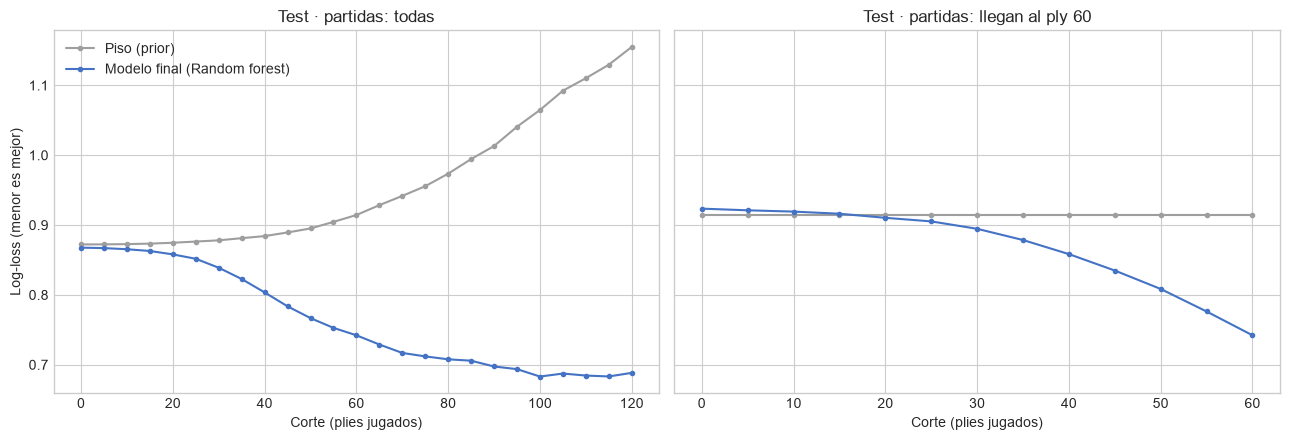

In [14]:
reaches_60 = test["GameUrl"].isin(set(test.loc[test["corte_ply"] == 60, "GameUrl"])).to_numpy()
curve_rows = []
for population, in_population, last in [("todas", np.ones(len(test), dtype=bool), max(CUTS)), ("llegan al ply 60", reaches_60, 60)]:
    for c in [c for c in CUTS if c <= last]:
        mask = in_population & (test_cut == c)
        curve_rows.append({"población": population, "corte_ply": c, "partidas": int(mask.sum()), **test_metrics(mask)})
curve = pd.DataFrame(curve_rows)
curve["mejora vs piso %"] = 100 * (1 - curve["log_loss"] / curve["log_loss piso"])
for population in ["todas", "llegan al ply 60"]:
    print(f"Población: {population}")
    shown = curve[(curve["población"] == population) & curve["corte_ply"].isin(REFERENCE_CUTS + [80, 100, 120])]
    display(shown.drop(columns="población").set_index("corte_ply"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, population in zip(axes, ["todas", "llegan al ply 60"]):
    sub = curve[curve["población"] == population]
    ax.plot(sub["corte_ply"], sub["log_loss piso"], color="#9e9e9e", marker="o", markersize=3, label="Piso (prior)")
    ax.plot(sub["corte_ply"], sub["log_loss"], color="#4472c4", marker="o", markersize=3, label=f"Modelo final ({CHOSEN_NAME})")
    ax.set(xlabel="Corte (plies jugados)", title=f"Test · partidas: {population}")
axes[0].set_ylabel("Log-loss (menor es mejor)")
axes[0].legend()
plt.tight_layout()
plt.show()

**Lectura de la curva.** En todo el test, el modelo final da 0,799 de log-loss contra 0,909 del piso, un 12 % mejor. Pero el promedio esconde la forma de la respuesta:

- **Antes de empezar, no se le gana al piso.** En el corte 0, 0,868 contra 0,872 (0,5 %). En la población común, 0,923 contra 0,914: un poco peor. Con lo que se sabe antes de mover, el resultado no se predice mejor que con las proporciones.
- **La ventaja aparece con el juego.** Se despega del piso entre el ply 20 y el 30, y crece sin parar: 9 % al ply 40, 19 % al 60, 27 % al 80 y 40 % al 120.
- **La comparación justa es la de la derecha.** En la curva de la izquierda, el piso empeora con los cortes porque usa las proporciones de todas las filas, y las partidas que siguen vivas a esa altura empatan más. Además, cada corte describe partidas distintas (sesgo de supervivencia). La de la derecha usa las mismas 10.302 partidas, las que llegan al ply 60, en todos los cortes. Ahí el modelo empata con el piso hasta el ply 20, y le gana un 2 % al 30, un 6 % al 40 y un 19 % al 60.

### Dónde se equivoca

La clase predicha es la de mayor probabilidad. La matriz normalizada **por fila** dice, de cada resultado real, qué se predijo (recall en la diagonal). La normalizada **por columna** dice, de cada predicción, qué pasó (precisión en la diagonal).

In [15]:
def confusion_table(mask, normalize):
    matrix = confusion_matrix(y_test[mask], predicted[mask], labels=RESULT_ORDER, normalize=normalize)
    return pd.DataFrame(matrix * 100, index=pd.Index(RESULT_ORDER, name="real"), columns=pd.Index(RESULT_ORDER, name="predicho"))


everything = np.ones(len(test), dtype=bool)
print("Todo el test, normalizada por fila (%): de cada resultado real, qué se predijo")
display(confusion_table(everything, "true"))
print("Todo el test, normalizada por columna (%): de cada predicción, qué pasó")
display(confusion_table(everything, "pred"))
print(classification_report(y_test, predicted, labels=RESULT_ORDER, digits=3, zero_division=0))
print("Sólo el corte 60, normalizada por fila (%)")
display(confusion_table(test_cut == 60, "true"))

Todo el test, normalizada por fila (%): de cada resultado real, qué se predijo


predicho,Gana Blancas,Empate,Gana Negras
real,,,
Gana Blancas,70.361,0.385,29.255
Empate,54.739,4.046,41.214
Gana Negras,42.456,0.390,57.153


Todo el test, normalizada por columna (%): de cada predicción, qué pasó


predicho,Gana Blancas,Empate,Gana Negras
real,,,
Gana Blancas,58.973,27.486,32.518
Empate,7.328,46.140,7.317
Gana Negras,33.700,26.374,60.164


              precision    recall  f1-score   support

Gana Blancas      0.590     0.704     0.642    115589
      Empate      0.461     0.040     0.074     18462
 Gana Negras      0.602     0.572     0.586    109465

    accuracy                          0.594    243516
   macro avg      0.551     0.439     0.434    243516
weighted avg      0.585     0.594     0.574    243516

Sólo el corte 60, normalizada por fila (%)


predicho,Gana Blancas,Empate,Gana Negras
real,,,
Gana Blancas,74.546,0.102,25.352
Empate,51.292,0.492,48.216
Gana Negras,26.930,0.153,72.918


In [16]:
# A concrete confusion, read from the board: rows from ply 60 on.
late = test_cut >= 60
late_frame = pd.DataFrame({
    "real": y_test[late], "predicho": predicted[late],
    "p_empate": proba_test[late, classes.index("Empate")],
    "balance": test.loc[late, "balance_material"].to_numpy(),
    # How the game ended: a post-game column, used here only to read the error, never as a feature.
    "final": test.loc[late, "GameUrl"].map(games.set_index("GameUrl")["Termination"]).to_numpy(),
})
display(late_frame.groupby("real").agg(
    filas=("real", "size"),
    p_empate_media=("p_empate", "mean"),
    predicho_empate=("predicho", lambda s: (s == "Empate").mean()),
    material_parejo=("balance", lambda s: (s.abs() <= 1).mean()),
).reindex(RESULT_ORDER))

decisive = late_frame[(late_frame["real"] != "Empate") & (late_frame["predicho"] != "Empate")]
flipped = decisive[decisive["real"] != decisive["predicho"]]
ahead = np.where(flipped["predicho"] == "Gana Blancas", flipped["balance"] > 0, flipped["balance"] < 0)
print(f"Desde el ply 60, el modelo erra el ganador en {len(flipped):,} de {len(decisive):,} filas de partidas decisivas "
      f"({len(flipped) / len(decisive) * 100:.1f} %). En esas, el bando que predijo iba arriba en material en el "
      f"{ahead.mean() * 100:.1f} % y estaban parejos en el {(flipped['balance'] == 0).mean() * 100:.1f} %.")
print("Cómo terminaron (% de filas):")
display(pd.DataFrame({
    "todas las decisivas": decisive["final"].value_counts(normalize=True),
    "erradas, con el predicho arriba en material": flipped.loc[ahead, "final"].value_counts(normalize=True),
}).mul(100).fillna(0).head(5))

,filas,p_empate_media,predicho_empate,material_parejo
real,,,,
Gana Blancas,30471,0.116,0.014,0.352
Empate,8193,0.200,0.091,0.492
Gana Negras,29353,0.121,0.014,0.348


Desde el ply 60, el modelo erra el ganador en 11,869 de 58,962 filas de partidas decisivas (20.1 %). En esas, el bando que predijo iba arriba en material en el 64.7 % y estaban parejos en el 20.5 %.
Cómo terminaron (% de filas):


,todas las decisivas,"erradas, con el predicho arriba en material"
final,,
time,42.689,52.135
checkmate,29.253,22.546
resignation,24.811,22.468
abandoned,3.248,2.851


**Lectura de la confusión.**

- **El empate casi no se predice.** De los empates reales, sólo el 4 % sale como empate; el resto se reparte entre blancas (55 %) y negras (41 %). Pero cuando el modelo sí dice empate, acierta el 46 % de las veces, seis veces su frecuencia: sabe reconocer las partidas con cara de tablas, aunque casi nunca le alcanza para que el empate sea la clase más probable. Desde el ply 60, las partidas que terminan en tablas reciben en promedio 0,20 de probabilidad de empate, contra 0,12 las decisivas, y la mitad tiene el material parejo. Es lo esperable en el online: las tablas salen de posiciones parejas, pero la mayoría de las posiciones parejas igual las termina ganando alguien.
- **Se inclina hacia blancas.** El recall es 70 % para Gana Blancas y 57 % para Gana Negras. En los cortes tempranos, sin información, la clase más probable es la mayoritaria: Gana Blancas, por la ventaja de mover primero (H4′ del notebook 02). Todo lo dudoso cae para ese lado. Al ply 60 la asimetría casi desaparece (74,5 % contra 72,9 %).
- **Una confusión concreta: el bando con más material que pierde.** Desde el ply 60, el modelo erra el ganador en el 20 % de las filas de partidas decisivas, y en el 65 % de esos errores el bando que eligió iba arriba en material. La mitad de esos errores terminan por tiempo (52 %, contra 43 % de todas las partidas decisivas): el que iba ganando en el tablero perdió con el reloj. Los demás son mates y abandonos: una jugada que dio vuelta la partida. El modelo sigue al material, que es lo correcto la mayoría de las veces. Lo que no puede ver es lo que todavía no pasó.

### En qué se apoya

Importancia por permutación sobre una muestra de test, con la métrica declarada: cuánto empeora la log-loss si una columna se vuelve ruido. Es importancia **del modelo**, no un efecto causal. Las columnas que se parecen se reparten la importancia; por ejemplo, el material de cada bando y su diferencia.

Importancia por permutación sobre 20,000 filas de test (22 s)


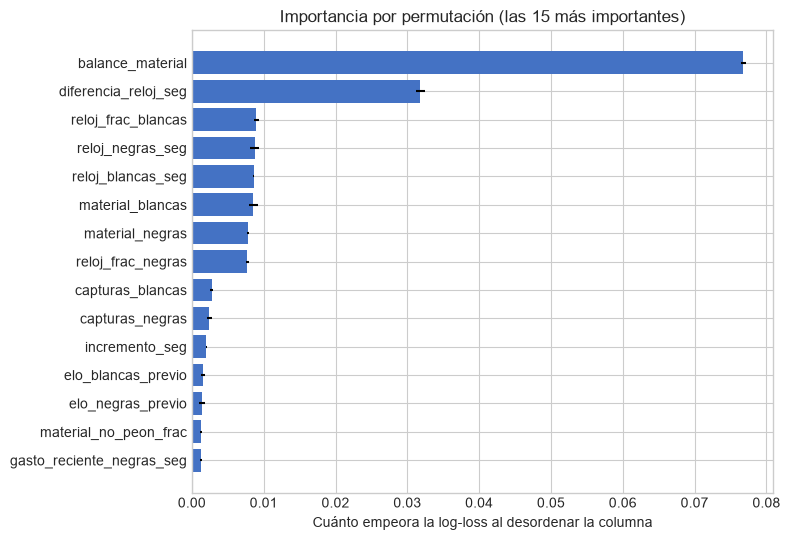

,media,desvío
balance_material,0.0768,0.0003
diferencia_reloj_seg,0.0318,0.0006
reloj_frac_blancas,0.0090,0.0003
reloj_negras_seg,0.0087,0.0006
reloj_blancas_seg,0.0086,0.0001
material_blancas,0.0085,0.0006
material_negras,0.0078,0.0002
reloj_frac_negras,0.0077,0.0002
capturas_blancas,0.0028,0.0002
capturas_negras,0.0025,0.0003


,media,desvío
promociones,0.0001,0.0000
en_jaque,0.0000,0.0000
derechos_enroque_blancas,0.0000,0.0000
derechos_enroque_negras,0.0000,0.0000
corte_ply,0.0000,0.0001
enroco_negras,-0.0001,0.0001
jaques_blancas,-0.0001,0.0001
tiempo_base_seg,-0.0001,0.0001


In [17]:
sample = test.sample(n=20_000, random_state=RANDOM_STATE)
started = time.perf_counter()
importance = permutation_importance(
    final_model, model_frame(sample, FINAL_COLUMNS), sample["resultado"].astype(str),
    scoring="neg_log_loss", n_repeats=3, random_state=RANDOM_STATE,
)
importance = pd.DataFrame({"media": importance.importances_mean, "desvío": importance.importances_std}, index=FINAL_COLUMNS)
importance = importance.sort_values("media", ascending=False)
print(f"Importancia por permutación sobre {len(sample):,} filas de test ({time.perf_counter() - started:.0f} s)")

top = importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top["media"], xerr=top["desvío"], color="#4472c4")
ax.set(xlabel="Cuánto empeora la log-loss al desordenar la columna", title="Importancia por permutación (las 15 más importantes)")
plt.tight_layout()
plt.show()
with pd.option_context("display.float_format", "{:.4f}".format):
    display(importance.head(10))
    display(importance.tail(8))

**Lectura.** La columna que más pesa es `balance_material`: desordenarla empeora la log-loss en 0,077, más del doble que la segunda, `diferencia_reloj_seg` (0,032). Después vienen los relojes y el material de cada lado, que se reparten importancia con esas dos. Ninguna sorprende: es lo que mira cualquier jugador para saber quién va ganando.

**Por qué no es una fuga.** `balance_material` en el corte *k* se calcula reproduciendo la partida con python-chess **sólo hasta el ply *k*** (`src/live_features.py`). El test `test_features_ignore_everything_after_the_cut` lo verifica: dos partidas con las mismas 10 primeras jugadas y continuaciones distintas dan exactamente la misma fila en el corte 10. Además, el comportamiento es el de una columna limpia: la mejora sobre el piso crece a medida que se captura material (la curva de la sección 8), y en el corte 0, donde el balance es 0 en todas las partidas, el modelo empata con el piso. Una columna con fuga daría un salto desde el principio.

**Al final de la lista** quedan columnas con importancia cero o negativa: promociones, jaque, derechos de enroque, `corte_ply`. No le agregan nada al modelo una vez que tiene el material y los relojes. Que `corte_ply` dé cero no quiere decir que el momento no importe: el material que queda y los relojes ya dicen en qué parte de la partida se está.

## 9 · ¿Sirve en cualquier jugada?

El modelo se entrenó con un corte cada 5 plies, pero la app predice en todas las jugadas. Como `corte_ply` es una columna numérica, el modelo puede evaluarse en el ply 47 aunque nunca haya visto ese valor. Hay que comprobar que ahí rinde como en los cortes vecinos.

Sobre 1.000 partidas de test se usa `predecir()` de `src/predict.py`, la misma función que va a usar la app, ply por ply. Primero se verifica que, en los plies del dataset, `predecir()` dé exactamente las mismas probabilidades que el camino de entrenamiento: así el código de la app no puede desviarse del modelo evaluado. Después se compara la log-loss de los plies intermedios con la que se obtiene interpolando entre los cortes vecinos. No es una decisión: es una medición más del modelo final.

In [18]:
check_games = sorted(pd.Series(sorted(test_games)).sample(n=1_000, random_state=RANDOM_STATE))
wanted = set(check_games)
pgns = {}
for path in raw_paths.values():
    with Path(path).open(encoding="utf-8") as file:
        for game in json.load(file).get("games", []):
            if game.get("url") in wanted:
                pgns.setdefault(game["url"], game["pgn"])
assert len(pgns) == len(wanted), "Falta el PGN crudo de alguna partida"

in_memory = {"resultado": final_model, "columnas": FINAL_COLUMNS}
context = games.set_index("GameUrl").loc[check_games, PRE_GAME + FORM]
started = time.perf_counter()
per_ply = pd.concat(
    [predecir(pgns[url], context.loc[url].to_dict(), in_memory).assign(GameUrl=url) for url in check_games],
    ignore_index=True,
)
rows_before = len(per_ply)
per_ply = per_ply.merge(games[["GameUrl", "resultado", "cantidad_jugadas"]], on="GameUrl", how="left", validate="many_to_one")
assert len(per_ply) == rows_before, "Fan-out detectado al unir el resultado"
print(f"{len(per_ply):,} predicciones (una por ply) de {len(check_games):,} partidas en {time.perf_counter() - started:.0f} s")

# Same features, same model: at the dataset cuts, predecir must reproduce the training-path probabilities.
test_rows = test[["GameUrl", "corte_ply"]].reset_index(names="fila")
on_cuts = per_ply.merge(test_rows, left_on=["GameUrl", "ply"], right_on=["GameUrl", "corte_ply"], how="inner", validate="one_to_one")
for label in RESULT_ORDER:
    np.testing.assert_allclose(on_cuts[label].to_numpy(), proba_test[on_cuts["fila"].to_numpy(), classes.index(label)], atol=1e-9)
print(f"predecir() reproduce las {len(on_cuts):,} predicciones del dataset en los plies de corte")

76,943 predicciones (una por ply) de 1,000 partidas en 49 s
predecir() reproduce las 15,384 predicciones del dataset en los plies de corte


654 partidas que llegan al ply 60. En los plies intermedios, log-loss media 0.8880 contra 0.8882 interpolando los cortes vecinos (diferencia media -0.0002; la mayor, en valor absoluto, 0.0176)


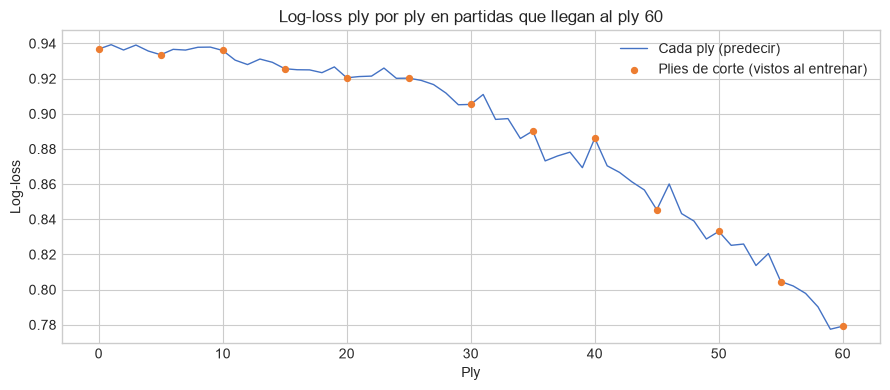

In [19]:
def ply_log_loss(frame):
    return log_loss(frame["resultado"], frame[classes].to_numpy(), labels=classes)


# Common population, as in section 8: games still going at ply 60, so every ply compares the same games.
common = per_ply[(per_ply["cantidad_jugadas"] > 60) & (per_ply["ply"] <= 60)]
by_ply = common.groupby("ply")[["resultado", *classes]].apply(ply_log_loss)
on_grid = by_ply[by_ply.index % 5 == 0]
interpolated = pd.Series(np.interp(by_ply.index, on_grid.index, on_grid.to_numpy()), index=by_ply.index)
off_grid = by_ply.index % 5 != 0
gap = (by_ply - interpolated)[off_grid]
print(f"{common['GameUrl'].nunique()} partidas que llegan al ply 60. En los plies intermedios, log-loss media {by_ply[off_grid].mean():.4f} "
      f"contra {interpolated[off_grid].mean():.4f} interpolando los cortes vecinos "
      f"(diferencia media {gap.mean():+.4f}; la mayor, en valor absoluto, {gap.abs().max():.4f})")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(by_ply.index, by_ply.to_numpy(), color="#4472c4", linewidth=1, label="Cada ply (predecir)")
ax.scatter(on_grid.index, on_grid.to_numpy(), color="#ed7d31", zorder=3, s=18, label="Plies de corte (vistos al entrenar)")
ax.set(xlabel="Ply", ylabel="Log-loss", title="Log-loss ply por ply en partidas que llegan al ply 60")
ax.legend()
plt.tight_layout()
plt.show()

**Lectura.**

- **La app usa el modelo evaluado.** En los 15.384 plies que están en el dataset, `predecir()` da exactamente las mismas probabilidades que el camino de entrenamiento (hasta 1e-9), no una copia aproximada.
- **Los plies intermedios rinden igual.** Sobre 654 partidas que llegan al ply 60, la log-loss en los plies que no son múltiplo de 5 es 0,8880, contra 0,8882 interpolando entre los cortes vecinos. La mayor diferencia en un ply es 0,018.

La curva no tiene saltos en los plies de corte: el modelo se comporta igual en el ply 47 que en el 45 y el 50. La app puede mostrar la probabilidad jugada a jugada.

## 10 · Objetivo secundario: la duración restante

Cuántos medio-movimientos faltan desde el corte (`plies_restantes`). Es una regresión, y se mide con el **error absoluto medio** (MAE), que se lee en plies: "le erramos por N plies en promedio". El piso es `DummyRegressor(strategy="median")` y el modelo simple, una regresión lineal con el mismo preprocesamiento. Se compara con un gradient boosting que optimiza el error absoluto, con la misma validación y las mismas columnas del clasificador final. No hay grilla propia: si el boosting fue el elegido para el resultado, usa esos hiperparámetros.

In [20]:
def make_regressor(family, columns):
    categorical = [c for c in columns if c in CATEGORICAL]
    numeric = [c for c in columns if c not in CATEGORICAL]
    if family == "mediana":
        return DummyRegressor(strategy="median")
    if family == "lineal":
        prep = ColumnTransformer([
            ("categoricas", OneHotEncoder(handle_unknown="ignore"), categorical),
            ("numericas", Pipeline([
                ("imputar", SimpleImputer(strategy="median", add_indicator=True)), ("escalar", StandardScaler()),
            ]), numeric),
        ])
        return Pipeline([("prep", prep), ("modelo", LinearRegression())])
    if family == "boosting":
        prep = ColumnTransformer(
            [("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical),
             ("numericas", "passthrough", numeric)],
            verbose_feature_names_out=False,
        ).set_output(transform="pandas")
        model = HistGradientBoostingRegressor(
            loss="absolute_error", categorical_features=categorical, early_stopping=False, random_state=RANDOM_STATE
        )
        return Pipeline([("prep", prep), ("modelo", model)])
    raise ValueError(f"Familia desconocida: {family}")


DURATION_PARAMS = {k: v for k, v in BEST_PARAMS.items() if k != "modelo__class_weight"} if CHOSEN_FAMILY == "boosting" else {}
REGRESSORS = {"Piso (mediana)": "mediana", "Regresión lineal": "lineal", "Gradient boosting": "boosting"}
X_cv_final = model_frame(cv_data, FINAL_COLUMNS)
duration_cv = {}
for name, family in REGRESSORS.items():
    regressor = make_regressor(family, FINAL_COLUMNS)
    if family == "boosting":
        regressor.set_params(**DURATION_PARAMS)
    result = cross_validate(regressor, X_cv_final, cv_data["plies_restantes"].to_numpy(dtype=float), cv=FOLDS,
                            scoring="neg_mean_absolute_error", return_train_score=True)
    duration_cv[name] = {"MAE": -result["test_score"].mean(), "± MAE": result["test_score"].std(),
                         "MAE train": -result["train_score"].mean(), "_folds": -result["test_score"]}
display(pd.DataFrame(duration_cv).T.drop(columns="_folds"))

DURATION_NAME = SIMPLE_REGRESSOR = "Regresión lineal"
diff = duration_cv["Gradient boosting"]["_folds"] - duration_cv[SIMPLE_REGRESSOR]["_folds"]
if diff.mean() < -diff.std(ddof=1):
    DURATION_NAME = "Gradient boosting"
print(f"Boosting − lineal: {diff.mean():+.2f} ± {diff.std(ddof=1):.2f} plies por pedazo → regresor elegido: {DURATION_NAME}")

,MAE,± MAE,MAE train
Piso (mediana),26.358,0.657,25.941
Regresión lineal,22.380,0.693,21.538
Gradient boosting,21.774,0.569,19.394


Boosting − lineal: -0.61 ± 0.17 plies por pedazo → regresor elegido: Gradient boosting


,MAE piso,MAE modelo,mejora %
corte_ply,,,
todos,26.306,20.969,20.288
0,37.846,25.710,32.067
10,31.504,25.274,19.775
20,27.061,24.337,10.068
30,24.532,23.031,6.120
40,23.404,21.459,8.314
60,22.879,17.921,21.672
80,22.798,15.091,33.806
100,23.337,13.181,43.521


,filas,MAE,sesgo_medio
tramo real,,,
1-10,29880,18.028,17.786
11-20,30409,15.146,13.891
21-40,59127,12.640,6.547
41-60,50380,13.659,-5.269
61-100,55437,26.762,-26.016
más de 100,18283,64.972,-64.972


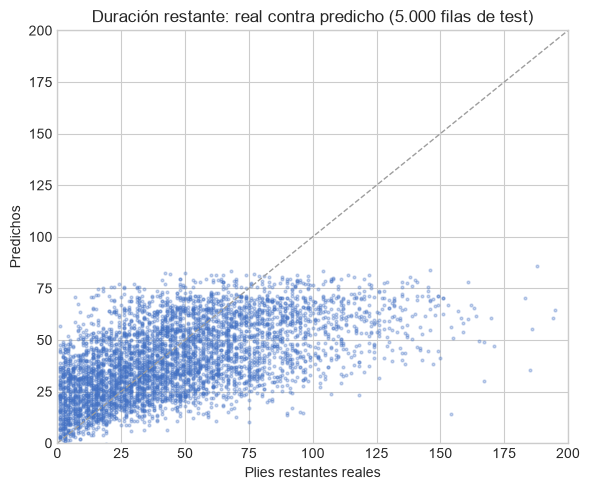

In [21]:
y_train_dur, y_test_dur = train["plies_restantes"].to_numpy(dtype=float), test["plies_restantes"].to_numpy(dtype=float)
final_regressor = make_regressor(REGRESSORS[DURATION_NAME], FINAL_COLUMNS)
if REGRESSORS[DURATION_NAME] == "boosting":
    final_regressor.set_params(**DURATION_PARAMS)
final_regressor.fit(X_train, y_train_dur)
floor_regressor = make_regressor("mediana", FINAL_COLUMNS).fit(X_train, y_train_dur)
pred_dur, pred_floor_dur = final_regressor.predict(X_test), floor_regressor.predict(X_test)

duration_rows = [{"corte_ply": "todos", "MAE piso": mean_absolute_error(y_test_dur, pred_floor_dur),
                  "MAE modelo": mean_absolute_error(y_test_dur, pred_dur)}]
for c in REFERENCE_CUTS + [80, 100, 120]:
    mask = test_cut == c
    duration_rows.append({"corte_ply": c, "MAE piso": mean_absolute_error(y_test_dur[mask], pred_floor_dur[mask]),
                          "MAE modelo": mean_absolute_error(y_test_dur[mask], pred_dur[mask])})
duration_test = pd.DataFrame(duration_rows).set_index("corte_ply")
duration_test["mejora %"] = 100 * (1 - duration_test["MAE modelo"] / duration_test["MAE piso"])
display(duration_test)

# Real against predicted, and in which range of the target the error is largest.
ranges = pd.cut(y_test_dur, bins=[0, 10, 20, 40, 60, 100, 1000], labels=["1-10", "11-20", "21-40", "41-60", "61-100", "más de 100"])
by_range = pd.DataFrame({"tramo real": ranges, "error": np.abs(pred_dur - y_test_dur), "sesgo": pred_dur - y_test_dur})
display(by_range.groupby("tramo real", observed=True).agg(filas=("error", "size"), MAE=("error", "mean"), sesgo_medio=("sesgo", "mean")))

fig, ax = plt.subplots(figsize=(6, 5))
shown = np.random.default_rng(RANDOM_STATE).choice(len(y_test_dur), size=5_000, replace=False)
ax.scatter(y_test_dur[shown], pred_dur[shown], s=4, alpha=0.3, color="#4472c4")
ax.plot([0, 200], [0, 200], color="#9e9e9e", linestyle="--", linewidth=1)
ax.set(xlim=(0, 200), ylim=(0, 200), xlabel="Plies restantes reales", ylabel="Predichos",
       title="Duración restante: real contra predicho (5.000 filas de test)")
plt.tight_layout()
plt.show()

**Lectura.**

- **Validación cruzada.** La regresión lineal ya le gana a la mediana: 22,4 ± 0,7 plies contra 26,4 ± 0,7. El boosting le gana a la lineal por 0,6 ± 0,2 plies pedazo a pedazo. Es poco, pero más que el ruido, así que queda el boosting.
- **Test.** Erra por 21,0 plies en promedio, contra 26,3 del piso (20 % mejor).
- **Por corte**, la mejora es grande al principio (32 % en el corte 0, porque el ritmo ya dice mucho de cuánto dura una partida) y al final (53 % al ply 120, porque con poco material queda poca partida). En el medio es chica (6 % al ply 30), justo donde el abanico de finales posibles es más ancho.
- **Dónde erra más.** La tabla por tramo muestra el patrón de una regresión que no ve el futuro. Cuando faltan pocas jugadas (1–10) predice 18 de más; cuando faltan más de 100, 65 de menos. El modelo tira hacia la duración típica, y lo que termina una partida —un error que la decide, un abandono, el reloj— no se ve venir en el tablero. El gráfico de real contra predicho lo muestra: la nube queda acostada respecto de la diagonal.

## 11 · Modelo guardado para la app

Se guarda un solo archivo con los dos pipelines (resultado y plies restantes) y la lista de columnas. Después se vuelve a cargar desde disco y se usa con `predecir()`, como lo va a hacer la app. `models/` no se versiona: lo regenera este notebook.

Guardado en models/modelo_en_vivo.joblib (99.8 MB)


Ejemplo: blitz, 101 plies, Gana Blancas por checkmate. El ganador llegó a 1.4 % en el ply 95.


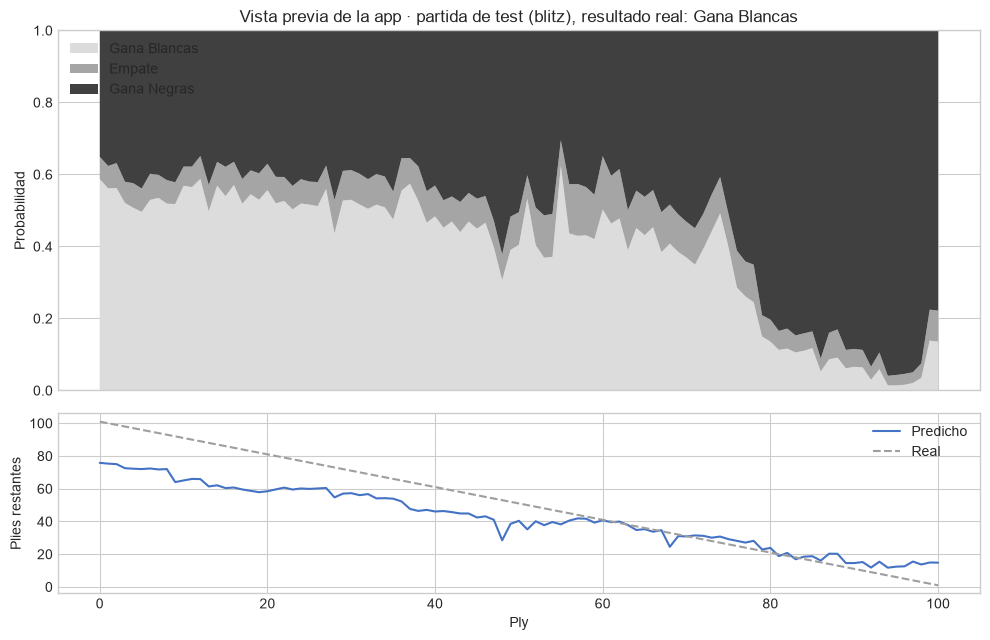

In [22]:
artifact = {
    "resultado": final_model,
    "plies_restantes": final_regressor,
    "columnas": FINAL_COLUMNS,
    "familia": CHOSEN_NAME,
    "hiperparametros": BEST_PARAMS,
    "entrenado_hasta": split_time.isoformat(),
    "cortes_entrenamiento": CUTS,
}
model_path = PROJECT_ROOT / MODEL_PATH
model_path.parent.mkdir(exist_ok=True)
joblib.dump(artifact, model_path, compress=3)
reloaded = cargar_modelo(model_path)
print(f"Guardado en {MODEL_PATH} ({model_path.stat().st_size / 1e6:.1f} MB)")

# Preview of what the app shows: the test game of the sample where the eventual winner fell lowest.
winner_proba = per_ply.apply(lambda row: row[row["resultado"]], axis=1)
decisive_long = per_ply[(per_ply["resultado"] != "Empate") & (per_ply["cantidad_jugadas"] >= 60)]
low_point = winner_proba.loc[decisive_long.index].groupby(decisive_long["GameUrl"]).min()
example_url = low_point.sort_values(kind="stable").index[0]
example = predecir(pgns[example_url], context.loc[example_url].to_dict(), reloaded)
np.testing.assert_allclose(
    example[RESULT_ORDER].to_numpy(), per_ply.loc[per_ply["GameUrl"] == example_url, RESULT_ORDER].to_numpy(), atol=1e-9
)
outcome = games.set_index("GameUrl").loc[example_url]
lowest = example.loc[example[outcome["resultado"]].idxmin()]
print(f"Ejemplo: {outcome['TimeClass']}, {outcome['cantidad_jugadas']} plies, {outcome['resultado']} por {outcome['Termination']}. "
      f"El ganador llegó a {lowest[outcome['resultado']] * 100:.1f} % en el ply {int(lowest['ply'])}.")

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, height_ratios=[2, 1])
axes[0].stackplot(example["ply"], example["Gana Blancas"], example["Empate"], example["Gana Negras"],
                  labels=RESULT_ORDER, colors=["#dcdcdc", "#a5a5a5", "#404040"])
axes[0].set(ylabel="Probabilidad", ylim=(0, 1),
            title=f"Vista previa de la app · partida de test ({outcome['TimeClass']}), resultado real: {outcome['resultado']}")
axes[0].legend(loc="upper left")
axes[1].plot(example["ply"], example["plies_restantes"], color="#4472c4", label="Predicho")
axes[1].plot(example["ply"], outcome["cantidad_jugadas"] - example["ply"], color="#9e9e9e", linestyle="--", label="Real")
axes[1].set(xlabel="Ply", ylabel="Plies restantes")
axes[1].legend()
plt.tight_layout()
plt.show()

**Lectura.** Es lo que va a mostrar la app, jugada a jugada. La partida elegida es la de la muestra en la que el ganador real llegó más abajo: una partida de blitz de 101 plies. Las probabilidades se mueven parejas durante casi toda la partida, negras pasa a ser clara favorita desde el ply 75, y en el ply 95 el modelo le daba a blancas un 1,4 %; ganaron blancas, por mate. Es justo el caso que el modelo no puede ver: una posición ganada que se pierde en las últimas jugadas. Abajo, la duración: al principio subestima lo que falta, y se va acomodando a medida que la partida avanza.

El archivo pesa ~100 MB, casi todo del bosque. Para la app alcanza. Si molestara, se puede achicar con menos árboles o con hojas más grandes, a un costo que la tabla de la sección 5 ya mide.

## 12 · Conclusiones

Las seis preguntas de la consigna, con los números de este notebook.

**Por qué esa métrica.** La app muestra probabilidades. El error caro es una probabilidad muy segura y equivocada, y la log-loss es la métrica que lo castiga. El F1 macro y el recall de Empate dejan a la vista a la clase chica, que el modelo casi no predice.

**Cuánto le gana al piso.** Un 12 % de log-loss en todo el test: 0,799 contra 0,909. Antes de mover, nada: con lo que se sabe antes de empezar, el resultado es tan predecible como las proporciones. Durante la partida, cada vez más: 19 % al ply 60 y 40 % al 120. Para la app alcanza, porque lo que se quiere mostrar es cómo cambian las probabilidades a medida que avanza la partida, y esa curva el modelo la tiene. Para anticipar el resultado antes de que empiece, no sirve.

**Por qué los pedazos se arman así.** Las filas se repiten por partida y la app predice partidas futuras, así que los pedazos son temporales y por partida. Con pedazos al azar, la log-loss da 0,011 mejor de lo real (0,810 contra 0,821), porque todas las filas de validación tienen otro corte de su misma partida en entrenamiento. Con jugadores nuevos casi no cambia (0,824).

**Por qué ese modelo.** El random forest le gana a la logística por 0,019 ± 0,0035, en los cinco pedazos. El boosting con valores por defecto no le gana a la logística por más que su desvío: memoriza (0,628 en train contra 0,890 en validación).

**Una confusión concreta.** El bando que va arriba en material y pierde: es el 65 % de los errores de ganador desde el ply 60. La mitad de esos errores terminan por tiempo (52 %, contra 43 % del total): el que iba ganando en el tablero perdió con el reloj.

**La columna que más pesa.** `balance_material`. Se calcula sólo con las jugadas hasta el corte, y un test lo garantiza. Además, en el corte 0, donde vale 0 en todas las partidas, el modelo empata con el piso: una fuga se notaría justamente ahí.

### Lo que probamos y no anduvo

- **Predecir antes de empezar.** Ningún modelo le gana al piso en el corte 0, ni en validación ni en test. Con el rating de un solo lado y un emparejamiento que junta jugadores parecidos, antes de la primera jugada no hay información para predecir.
- **La forma reciente del jugador** (últimas 10 partidas, racha, tendencia del rating, sesión). La idea era justamente mejorar el corte 0. Mejora 0,005 ahí, menos que su desvío, y no entró.
- **El rating previo.** Quitarlo no cambia la log-loss.
- **El matchup de apertura.** No aporta, ahora confirmado con validación cruzada.
- **Balancear el empate.** Sube su recall de 0,01 a 0,39, pero rompe las probabilidades: +0,137 de log-loss.
- **El gradient boosting con valores por defecto.** Memorizó los cortes de las mismas partidas y quedó último. No se ajustó porque no fue el elegido. Ajustado podría acercarse al bosque, y sería lo primero que probaríamos si hiciera falta un modelo más liviano (el bosque pesa ~100 MB).

### Limitaciones

- El rating previo y la forma sólo existen para la cuenta seleccionada: del rival no hay historial.
- La muestra son 100 cuentas elegidas por banda de ELO, no Chess.com en general.
- El modelo se entrenó con cortes hasta el ply 120. Más allá extrapola, y el 10 % de las partidas dura más.
- Cada corte describe partidas distintas (sesgo de supervivencia). La comparación justa entre cortes es la población común de la sección 8.
- La duración restante se subestima en las partidas largas y se sobreestima en las que están por terminar.

In [23]:
assert not set(LEAKY) & set(FINAL_COLUMNS), "Una columna con fuga entró al modelo final"
assert set(train["GameUrl"]).isdisjoint(test["GameUrl"])
assert games.loc[games["GameUrl"].isin(train_games), "EndTime"].max() < games.loc[games["GameUrl"].isin(test_games), "StartTime"].min(), \
    "Una partida de train termina después de que empieza una de test"
assert set(cv_data["GameUrl"]) <= train_games, "La validación cruzada vio una partida de test"
assert np.isfinite(curve["log_loss"]).all()
# Sanity bound: overall, the prior floor can never be worse than a uniform guess (ln 3).
assert log_loss(y_test, proba_floor, labels=floor_model.classes_) < np.log(3)
assert reloaded["columnas"] == FINAL_COLUMNS and list(reloaded["resultado"].classes_) == sorted(RESULT_ORDER)
print(f"Todos los chequeos pasaron. Tiempo total: {(time.perf_counter() - NOTEBOOK_START) / 60:.1f} min")

Todos los chequeos pasaron. Tiempo total: 16.0 min
